# Module 7 Lab: Regression, kNN and Decision Trees

**Author:** _Roey Kadur_  
**GitHub repo:** _https://github.com/roee0910/cs82a-portfolio.git_

Goal: train one regression and two classifiers with scikit-learn, evaluate them on held-out data, and write an honest model report.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree

import sklearn
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.1


## Part 1: Regression on tips.csv
### Step 1: Load tips.csv and frame the problem

In [2]:
df = pd.read_csv("tips.csv")
print(df.shape)
print(df.head())

X = df[["total_bill"]]   # double brackets -> 2D DataFrame (features)
y = df["tip"]            # target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

print("train rows:", len(X_train), "| test rows:", len(X_test))
assert len(X_train) in (170, 171), "unexpected training size"

(244, 7)
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4
train rows: 170 | test rows: 74


### Step 2: Why hold out 30%?

A model can score well simply by memorizing the rows it was trained on, so a score on the training data says nothing about how it will behave on new customers. By reserving 30% of the rows that the model never sees while learning, the test score estimates how well it generalizes to unseen data. This is the honest grade; training score alone is not.

### Step 3: Fit the regression and read the slope

In [3]:
reg = LinearRegression()
reg.fit(X_train, y_train)

slope = reg.coef_[0]
intercept = reg.intercept_
print("slope:", round(slope, 4))
print("intercept:", round(intercept, 4))
print("R^2 on TEST:", round(reg.score(X_test, y_test), 3))

assert 0.10 <= slope <= 0.11, "slope outside the expected 0.10-0.11 range - check X and y"

slope: 0.1089
intercept: 0.877
R^2 on TEST: 0.429


**Slope sentence:** each extra dollar of bill adds about **$0.11** (0.109) of tip, starting from an intercept of about $0.88.

The test R² is about 0.43, so the bill size explains well under half of the variation in tips. It is a useful but modest predictor.

### Step 4: Draw the fitted line

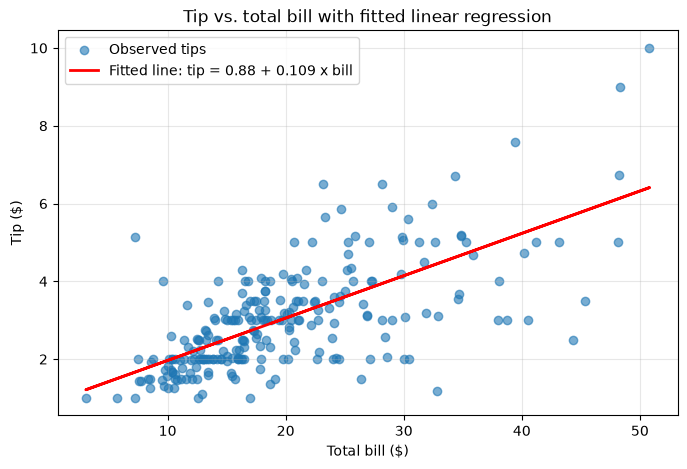

In [4]:
y_line = reg.predict(X)   # predicted tip for every bill

plt.figure(figsize=(8, 5))
plt.scatter(df["total_bill"], df["tip"], alpha=0.6, label="Observed tips")
plt.plot(df["total_bill"], y_line, color="red", linewidth=2,
         label=f"Fitted line: tip = {intercept:.2f} + {slope:.3f} x bill")
plt.xlabel("Total bill ($)")
plt.ylabel("Tip ($)")
plt.title("Tip vs. total bill with fitted linear regression")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Checkpoint passed:** the slope sentence (about 0.11) matches the printed coefficient (0.1089), and the plot shows an upward cloud with the line running through it.

## Part 2: Classification on iris
### Step 5: Load iris and split it

In [5]:
iris = load_iris(as_frame=True)
Xi = iris.data
yi = iris.target
print("total flowers:", len(Xi))
print("columns:", list(Xi.columns))
print("classes:", [str(n) for n in iris.target_names])

Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    Xi, yi, test_size=0.3, random_state=42)
print("train:", len(Xi_train), "| test:", len(Xi_test))
assert len(Xi) == 150 and len(Xi_train) == 105

total flowers: 150
columns: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
classes: ['setosa', 'versicolor', 'virginica']
train: 105 | test: 45


### Step 6: Fit and score kNN

In [6]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(Xi_train, yi_train)
knn_test = knn.score(Xi_test, yi_test)
print("kNN accuracy on TEST:", round(knn_test, 3))
assert 0.93 <= knn_test <= 1.0

kNN accuracy on TEST: 1.0


### Step 7: Fit, score, and read a shallow tree

Shallow tree (max_depth=3) accuracy on TEST: 1.0


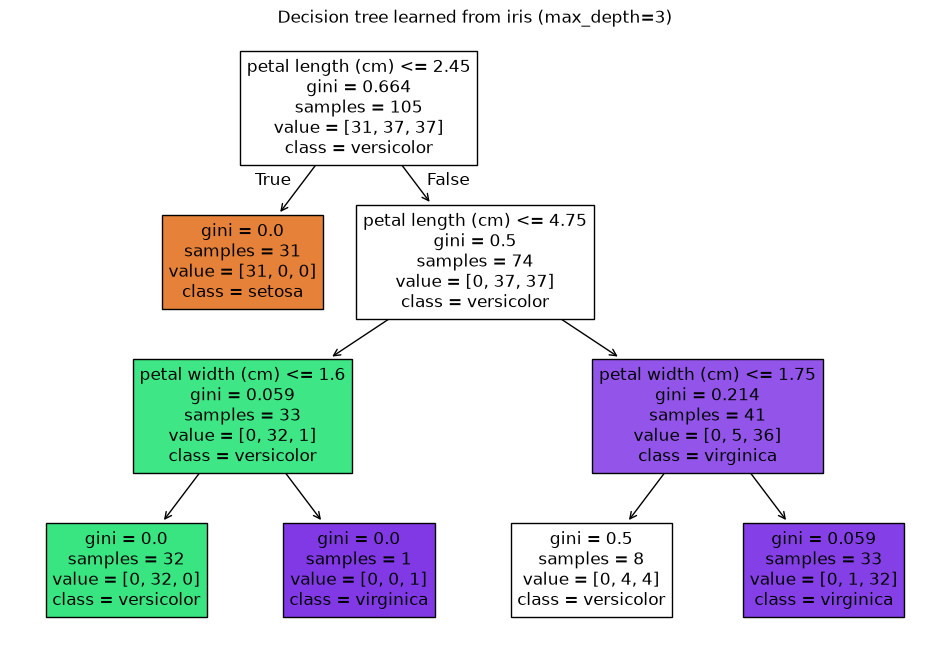

In [7]:
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(Xi_train, yi_train)
print("Shallow tree (max_depth=3) accuracy on TEST:", round(tree.score(Xi_test, yi_test), 3))

plt.figure(figsize=(12, 8))
plot_tree(tree, feature_names=list(Xi.columns),
          class_names=list(iris.target_names), filled=True)
plt.title("Decision tree learned from iris (max_depth=3)")
plt.show()

**Root split in plain words:** if a flower's petal length is 2.45 cm or less, the tree says it is *setosa*; otherwise it keeps asking questions (petal length again, then petal width) to separate *versicolor* from *virginica*.

### Step 8: The overfitting probe

In [8]:
tree_full = DecisionTreeClassifier(random_state=42)   # no max_depth
tree_full.fit(Xi_train, yi_train)

results = pd.DataFrame({
    "model": ["Tree max_depth=3", "Tree unlimited depth"],
    "depth": [tree.get_depth(), tree_full.get_depth()],
    "train accuracy": [tree.score(Xi_train, yi_train), tree_full.score(Xi_train, yi_train)],
    "test accuracy":  [tree.score(Xi_test, yi_test),  tree_full.score(Xi_test, yi_test)],
}).round(3)
print(results.to_string(index=False))

               model  depth  train accuracy  test accuracy
    Tree max_depth=3      3           0.952            1.0
Tree unlimited depth      6           1.000            1.0


**Observation:** the unlimited tree reaches 1.00 on the training data (it grows to depth 6 to fit every training flower), but it does not beat the shallow tree on the test set (both 1.00), so the extra complexity bought nothing.

On this particular split the gap between train and test is not visible, because the test set has only 45 flowers (one flower is about 2.2 points of accuracy), so a single split cannot show overfitting reliably. The optional check below uses 5-fold cross-validation to get a steadier comparison.

In [9]:
# Optional extra: more stable estimate than a single 45-flower test set
for name, model in [("kNN (k=5)", KNeighborsClassifier(n_neighbors=5)),
                    ("Tree max_depth=3", DecisionTreeClassifier(max_depth=3, random_state=42)),
                    ("Tree unlimited", DecisionTreeClassifier(random_state=42))]:
    scores = cross_val_score(model, Xi, yi, cv=5)
    print(f"{name:18s} 5-fold mean accuracy = {scores.mean():.3f}  (folds: {scores.round(2)})")

kNN (k=5)          5-fold mean accuracy = 0.973  (folds: [0.97 1.   0.93 0.97 1.  ])
Tree max_depth=3   5-fold mean accuracy = 0.973  (folds: [0.97 0.97 0.93 1.   1.  ])
Tree unlimited     5-fold mean accuracy = 0.953  (folds: [0.97 0.97 0.9  0.93 1.  ])


The cross-validated scores confirm the picture: kNN and the shallow tree tie at about 0.97, and the unlimited tree is slightly worse (about 0.95).

### Step 9: Predict one new flower

In [10]:
new_flower = pd.DataFrame([[5.9, 3.0, 4.2, 1.3]], columns=Xi.columns)
print(new_flower.to_string(index=False))
pred = tree.predict(new_flower)[0]
print("Predicted species:", iris.target_names[pred])

 sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
               5.9               3.0                4.2               1.3
Predicted species: versicolor


### Step 10: Model report
I predicted tip amount from the bill (linear regression, test R² ≈ 0.43, a modest predictor) and iris species from four measurements. I would ship the shallow decision tree (max_depth=3): it scored 1.00 on the 45 held-out flowers (≈0.97 under 5-fold cross-validation), matches kNN, and is a readable flowchart. It may fail on flowers in the versicolor/virginica overlap, on measurement errors, or on a species outside the training data, since it must choose one of three known classes. If this were a model about people, under-represented groups in the training data could get worse accuracy, so it would need per-group evaluation, not just one overall score.